# Biochemistry
*Enzyme kinetics: fitting a rate law with gradients*

An enzyme turns a substrate into a product, and as the substrate runs out the reaction slows. This page integrates that progress curve for many conditions at once, checks it against the exact Lambert W solution, and then fits the two rate parameters to noisy measurements by reverse-mode gradients through the integration, for hundreds of synthetic experiments in one call.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/anim.py",
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import gpu_available, plot_style, show, to_numpy, xp
plot_style()

## The reaction, once

One enzyme, one irreversible step, in the reduced Michaelis-Menten form that holds when there is much less enzyme than substrate: `dS/dt = -Vmax S / (Km + S)`, and the product `P` grows by the same amount, `dP/dt = +Vmax S / (Km + S)`. The model leaves out product inhibition, reversibility and the enzyme's own binding step. The substrate is depleted, so the rate falls as the curve goes on: that curvature is where the information about `Km` lives.

- Units: micromolar (µM) and minutes. `Vmax` is the top rate in µM/min and `Km`, in µM, is the substrate level at which the rate is half of it.
- The setting: `S0 = 100 µM` of substrate, `Vmax = 10 µM/min`, `Km = 30 µM`, measured every 1.5 min for 12 points (to 18 min), each with independent Gaussian noise of 1 µM.
- Closed form: `S(t) = Km W((S0 / Km) exp((S0 - Vmax t) / Km))`, with `W` the Lambert W function. It is the reference below. SciPy has `W`, but this page does not use SciPy: a few lines of Halley iteration in NumPy compute it.

Declare the experiment's words as a `KernelKind` once: the start substrate, the two rate parameters and the time of the measurement. One lane is one measurement of one experiment.

In [3]:
import numpy as np
import eagle
import hawk
import hawk.math as m
from hawk import Int32, Matrix, Mutable, Scalar, Vector
from hawk.ext import DATA_ONLY, KernelKind


class Enzyme(KernelKind, slug="enzyme"):
    S0: Scalar          # starting substrate (µM)
    Vmax: Scalar        # top rate (µM / min)
    Km: Scalar          # half-saturation substrate (µM)
    t_obs: Scalar       # time of this measurement (min)
    guard = DATA_ONLY

Enzyme

__main__.Enzyme

## One measurement

The kernel integrates from `0` to `t_obs` with a fixed number of classical Runge-Kutta (RK4) steps and writes the substrate and the product. The rate law is not stiff here: the rate's derivative with respect to `S` is `-Vmax Km / (Km + S)^2`, at most `Vmax / Km` in size, so the fastest condition of the grid below (20 µM/min, 10 µM) decays at 2 per minute, and an explicit fourth-order method is the right, plain tool. It is stable while `h` times that rate stays below 2.785, the edge of RK4's stability region on the real axis; the check below counts the steps against it. The number of steps is part of the kernel, so a small function builds the kernel for the step count you ask for.

Because each lane is one measurement, an experiment of 12 points is 12 lanes, and the whole ensemble is one flat call. That shape makes the derivatives of all 12 points one launch. It has a price: every lane integrates from `t = 0` with its own step `t_obs / nsteps`, which is 384 RK4 steps per experiment where one trajectory sampled at the 12 times would take about 36. The sum for a fit stays exact; the extra work is the cost of keeping the lanes independent.

In [4]:
def make_progress(nsteps):
    @Enzyme
    def progress(S0, Vmax, Km, t_obs, S: Mutable[Scalar], P: Mutable[Scalar]):
        h = t_obs / nsteps
        s = S0
        p = 0.0
        for _ in range(nsteps):
            k1 = Vmax * s / (Km + s)                 # the rate is -dS/dt
            s2 = s - 0.5 * h * k1
            k2 = Vmax * s2 / (Km + s2)
            s3 = s - 0.5 * h * k2
            k3 = Vmax * s3 / (Km + s3)
            s4 = s - h * k3
            k4 = Vmax * s4 / (Km + s4)
            v = (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0
            s = s - h * v
            p = p + h * v
        S = s
        P = p
    return progress


progress = make_progress(32)
progress

<Kernel progress slots=6>

## A sweep of conditions

A grid of 8 `Vmax` values from 5 to 20 µM/min and 8 `Km` values from 10 to 100 µM, each measured at the 12 times: 64 conditions, 768 lanes, one call. `eagle.deploy(progress).run(...)` takes the planes by name and returns `S` and `P` by name.

In [5]:
S0, V_TRUE, K_TRUE, SIGMA = 100.0, 10.0, 30.0, 1.0
M = 12
t_obs = 1.5 * np.arange(1, M + 1)                              # min

Vg, Kg = np.meshgrid(np.geomspace(5, 20, 8), np.geomspace(10, 100, 8), indexing="ij")
V_grid, K_grid = Vg.ravel(), Kg.ravel()                         # 64 conditions
model = eagle.deploy(progress)


def curves(Vs, Ks, t=t_obs, program=None):
    # S and P at the times `t`, one row per (Vmax, Km) pair
    n = len(Vs)
    run = (program or model).run
    out = run(S0=xp.full(n * len(t), S0), Vmax=xp.repeat(xp.asarray(Vs), len(t)), Km=xp.repeat(xp.asarray(Ks), len(t)),
              t_obs=xp.tile(xp.asarray(t), n))
    return xp.asarray(out["S"]).reshape(n, len(t)), xp.asarray(out["P"]).reshape(n, len(t))


S_grid, P_grid = (to_numpy(a) for a in curves(V_grid, K_grid))
print("substrate left after 18 min:", f"{S_grid[:, -1].min():.1f} to {S_grid[:, -1].max():.1f} µM across the 64 conditions")

substrate left after 18 min: 0.0 to 60.4 µM across the 64 conditions


## Check it against the exact solution

Three checks.

The exact solution first. `lambert_w` solves `w e^w = x` by Halley's iteration from `log(1 + x)`. The integrated substrate must match `Km W(...)` over all 768 lanes. RK4 is fourth order, so the error should fall by about 16 when the step count doubles; the table shows 4, 8 and 16 steps at the true parameters, and the kernel used has 32 (the kernel uses 32 for accuracy, not for stability; the stability check follows the table).

The second check is the stability line from above: `h` times the largest `Vmax / Km` of the grid, with the longest `h` of any lane, against 2.785. The third holds by construction: the substrate and product add up to `S0` at every time, because a Runge-Kutta step keeps any linear sum of the states exactly. It catches a sign or a factor wrong in the rate, not a bad scheme; the exact solution is the check that tests the scheme.

In [6]:
def lambert_w(x):
    # principal branch for x >= 0: Halley iteration on w e^w = x
    w = np.log1p(x)
    for _ in range(60):
        e = np.exp(w)
        f = w * e - x
        step = f / (e * (w + 1) - (w + 2) * f / (2 * w + 2))
        w = w - step
        if np.abs(step).max() < 1e-15:
            break
    return w


def exact_substrate(Vs, Ks, t=t_obs):
    Vs, Ks = np.asarray(Vs)[:, None], np.asarray(Ks)[:, None]
    z = (S0 / Ks) * np.exp((S0 - Vs * t) / Ks)
    return Ks * lambert_w(z), lambert_w(z)


S_exact, _ = exact_substrate(V_grid, K_grid)
assert np.abs(lambert_w(np.array([0.5, 3.0, 40.0])) * np.exp(lambert_w(np.array([0.5, 3.0, 40.0]))) - [0.5, 3.0, 40.0]).max() < 1e-12

errors = []
for nsteps in (4, 8, 16):
    S_n, _ = curves([V_TRUE], [K_TRUE], program=eagle.deploy(make_progress(nsteps)))
    errors.append(np.abs(to_numpy(S_n) - exact_substrate([V_TRUE], [K_TRUE])[0]).max())
    print(f"{nsteps:>3} RK4 steps: worst error against the exact solution {errors[-1]:.1e} µM")
ratios = [errors[i] / errors[i + 1] for i in range(2)]
assert all(12 < r < 28 for r in ratios), ratios
print(f"doubling the steps divides the error by {ratios[0]:.1f} and {ratios[1]:.1f}: fourth order")

LIMIT = 2.785                                                  # RK4's stability limit on the negative real axis
fastest = (V_grid / K_grid).max()                              # largest |d rate / dS| on the grid, per minute
for nsteps in (4, 8, 16, 32):
    edge = t_obs[-1] / nsteps * fastest
    print(f"{nsteps:>3} steps: h x fastest rate = {edge:.3f} -> {'stable' if edge < LIMIT else 'unstable'} (limit {LIMIT})")
    assert (edge < LIMIT) == (nsteps >= 16), (nsteps, edge)

TOL_S = 1e-3                                                   # µM, against a noise of 1 µM
worst = np.abs(S_grid - S_exact).max()
assert worst < TOL_S, worst
print(f"the kernel (32 steps): worst error {worst:.1e} µM < {TOL_S:g} µM over {S_grid.size} lanes")

assert np.abs(S_grid + P_grid - S0).max() < 1e-10
print(f"substrate + product = S0 at every time, worst gap {np.abs(S_grid + P_grid - S0).max():.1e} µM (by construction)")

  4 RK4 steps: worst error against the exact solution 1.4e-01 µM


  8 RK4 steps: worst error against the exact solution 6.7e-03 µM


 16 RK4 steps: worst error against the exact solution 3.6e-04 µM
doubling the steps divides the error by 21.1 and 18.8: fourth order
  4 steps: h x fastest rate = 9.000 -> unstable (limit 2.785)
  8 steps: h x fastest rate = 4.500 -> unstable (limit 2.785)
 16 steps: h x fastest rate = 2.250 -> stable (limit 2.785)
 32 steps: h x fastest rate = 1.125 -> stable (limit 2.785)
the kernel (32 steps): worst error 3.5e-04 µM < 0.001 µM over 768 lanes
substrate + product = S0 at every time, worst gap 7.1e-14 µM (by construction)


## The gradient for fitting

A fit needs `d S / d Vmax` and `d S / d Km` for each measurement. `hawk.diff.vjp(progress, wrt=("Vmax", "Km"))` derives the reverse-mode kernel; `eagle.deploy` takes the kernel and its derivative together. Each lane takes a seed `bar_S`, and returns `bar_Vmax` and `bar_Km`, the seed times the derivative. With a seed of one the result is the derivative itself; with the residual as the seed the sum over an experiment's 12 lanes is the gradient of its misfit.

Three checks on the derivative, at the true parameters.
- **Exactness:** a central finite difference of the same integration, in float64, with a relative step of 1e-6. It is the derivative of exactly what the kernel computes, so the tolerance is a rounding one.
- **Closed form:** from `W`, `dS/dVmax = -t W / (1 + W)` and `dS/dKm = W + Km W / (1 + W) d(ln z)/dKm` with `ln z = ln(S0/Km) + (S0 - Vmax t)/Km`. It differs from the kernel's derivative only by the scheme's error.

In [7]:
from hawk import Kernel
from hawk.diff import vjp

progress_vjp = Kernel("progress_vjp", vjp(progress, wrt=("Vmax", "Km")))
model, backward = eagle.deploy([progress, progress_vjp])


def jacobian(Vs, Ks, seed=1.0, t=t_obs):
    # d S / d Vmax and d S / d Km for each (Vmax, Km) pair and time; `seed` is bar_S, one number or one per lane
    n = len(Vs)
    ones = xp.ones(n * len(t))
    out = backward.run(S0=xp.full(n * len(t), S0), Vmax=xp.repeat(xp.asarray(Vs), len(t)), Km=xp.repeat(xp.asarray(Ks), len(t)),
                       t_obs=xp.tile(xp.asarray(t), n), bar_S=seed * ones, bar_P=0 * ones)
    return xp.asarray(out["bar_Vmax"]).reshape(n, len(t)), xp.asarray(out["bar_Km"]).reshape(n, len(t))


dV, dK = (to_numpy(a) for a in jacobian(V_grid, K_grid))

rel = 1e-6                                                     # exactness: central differences of the integration
dV_fd = (to_numpy(curves(V_grid * (1 + rel), K_grid)[0]) - to_numpy(curves(V_grid * (1 - rel), K_grid)[0])) / (2 * rel * V_grid[:, None])
dK_fd = (to_numpy(curves(V_grid, K_grid * (1 + rel))[0]) - to_numpy(curves(V_grid, K_grid * (1 - rel))[0])) / (2 * rel * K_grid[:, None])
TOL_GRAD = 1e-6
gap = max(np.abs(dV - dV_fd).max() / np.abs(dV).max(), np.abs(dK - dK_fd).max() / np.abs(dK).max())
assert gap < TOL_GRAD, gap
print(f"derivative against central differences over {dV.size} lanes: worst gap {gap:.1e} of the largest value < {TOL_GRAD:g}")

W = exact_substrate(V_grid, K_grid)[1]
Vc, Kc, tc = V_grid[:, None], K_grid[:, None], t_obs
dV_exact = -tc * W / (1 + W)
dK_exact = W + Kc * W / (1 + W) * (-1 / Kc - (S0 - Vc * tc) / Kc**2)
TOL_EXACT = 1e-3
gap_exact = max(np.abs(dV - dV_exact).max() / np.abs(dV_exact).max(), np.abs(dK - dK_exact).max() / np.abs(dK_exact).max())
assert gap_exact < TOL_EXACT, gap_exact
print(f"against the closed-form derivative: worst gap {gap_exact:.1e} of the largest value < {TOL_EXACT:g}")

derivative against central differences over 768 lanes: worst gap 2.9e-09 of the largest value < 1e-06
against the closed-form derivative: worst gap 9.0e-05 of the largest value < 0.001


## Fit 400 experiments at once

Now the experiment itself. Draw 400 synthetic data sets from the true parameters, each the clean curve plus 1 µM of Gaussian noise, and fit each one's `Vmax` and `Km` by minimising the misfit `L = (1/2) sum ((S - data) / sigma)^2`. This is the negative log-likelihood, so its minimum is the maximum-likelihood fit. For two parameters and twelve points a kineticist uses **Levenberg-Marquardt**, a damped Gauss-Newton method, and the page already has what it needs: `jacobian` with a seed of one returns each experiment's 12 x 2 matrix `J` of derivatives in one launch. Per iteration, in `ln Vmax` and `ln Km` (both stay positive, and a step means the same for both): residuals `r` from `curves`, `J` from `jacobian`, then `lm_kernel`, a hawk kernel with one lane per experiment that takes the 12 x 2 matrix `J` and the 12 residuals and returns the damped Gauss-Newton step `-(J^T J + mu I)^-1 J^T r` with `m.lm_step`. The step is part of the kernel's own vocabulary, so the whole fit stays on the same backend as the integration. A step that lowers the misfit is accepted and `mu` shrinks; one that does not is refused and `mu` grows. Start from `Vmax = 6`, `Km = 15`. The rate parameters are the only unknowns; `S0` is known.

In [8]:
@hawk.kernel
def lm_kernel(J: Matrix[12, 2], r: Vector[12], mu: Scalar, step: Mutable[Vector[2]]):
    step = m.lm_step(J, r, mu)                                       # -(J^T J + mu I)^-1 J^T r, one lane per experiment


lm_solver = eagle.deploy(lm_kernel)


def fit(data, iterations=60, start=(6.0, 15.0), trail=None):
    # maximum-likelihood Vmax and Km for each row of `data` (experiments x M), by Levenberg-Marquardt in log-parameters
    n = data.shape[0]
    theta = xp.log(xp.asarray(start))[:, None] * xp.ones((2, n))
    mu = xp.full(n, 1e-2)

    def residual_of(theta):
        return (curves(*xp.exp(theta), program=model)[0] - data) / SIGMA

    def normal_equations(theta):
        Vs, Ks = xp.exp(theta)
        gV, gK = jacobian(Vs, Ks)
        J = xp.stack([gV * Vs[:, None], gK * Ks[:, None]], axis=2) / SIGMA          # d residual / d ln theta: experiments x M x 2
        return J, xp.swapaxes(J, 1, 2) @ J

    r = residual_of(theta)
    misfit = 0.5 * (r**2).sum(axis=1)
    used = 0
    if trail is not None:
        trail.append(to_numpy(theta))
    for used in range(1, iterations + 1):
        J, A = normal_equations(theta)
        step = xp.asarray(lm_solver.run(J=xp.ascontiguousarray(J.reshape(n, -1).T), r=xp.ascontiguousarray(r.T), mu=mu))    # components first: (24, n), (12, n)
        trial = theta + step
        r_trial = residual_of(trial)
        misfit_trial = 0.5 * (r_trial**2).sum(axis=1)
        accept = misfit_trial < misfit
        theta = xp.where(accept, trial, theta)
        r = xp.where(accept[:, None], r_trial, r)
        misfit = xp.where(accept, misfit_trial, misfit)
        mu = xp.where(accept, xp.maximum(mu * 0.3, 1e-12), mu * 3.0)
        if trail is not None:
            trail.append(to_numpy(theta))
        if float(xp.abs(step).max()) < 1e-9:
            break
    J, A = normal_equations(theta)                                                  # J^T J at each fit: its own covariance
    return to_numpy(theta), to_numpy(misfit), to_numpy(A), used


rng = np.random.default_rng(1)
N = 400
clean = to_numpy(curves(np.array([V_TRUE]), np.array([K_TRUE]))[0])[0]
data = clean + SIGMA * rng.normal(size=(N, M))
trail = []
theta, misfit, fisher_fit, used = fit(xp.asarray(data), trail=trail)
V_fit, K_fit = np.exp(theta)
print(f"{N} experiments fitted in {used} Levenberg-Marquardt iterations")
print(f"Vmax: mean {V_fit.mean():.2f} µM/min (true {V_TRUE}), spread {V_fit.std():.2f};  Km: mean {K_fit.mean():.1f} µM (true {K_TRUE}), spread {K_fit.std():.1f}")

400 experiments fitted in 29 Levenberg-Marquardt iterations
Vmax: mean 10.00 µM/min (true 10.0), spread 0.45;  Km: mean 30.0 µM (true 30.0), spread 3.8


## Does the fit recover the truth, within its stated uncertainty?

The uncertainty of a maximum-likelihood fit to noise `sigma` is its Fisher covariance, `sigma^2 (J^T J)^-1`, with `J` the derivatives of the 12 curve points with respect to the parameters. Four checks against it:
- the spread of the 400 fitted values matches the covariance at the true parameters, within 15% (the standard deviation of 400 values is itself good to 3.5%, so 15% is more than four of its standard errors);
- the mean fitted value is within four standard errors of the mean (the predicted spread over `sqrt(400)`) of the truth;
- the misfit `2 L` follows a chi-squared law with `12 - 2` degrees of freedom, so its mean is 10 (standard error `sqrt(2 * 10 / 400)`);
- the true parameters fall inside each data set's own 95% region for about 95% of the data sets, and the check allows 90 to 99%. The region is the one a practitioner reports: the covariance at the fit itself, `J^T J` from the last iteration, not the one at the unknown truth. It is a linearised (Wald) region, and this model is curved and strongly correlated, so a little under 95% is expected; a profile-likelihood region is the practitioner's remedy.

In [9]:
jV, jK = (to_numpy(a)[0] for a in jacobian(np.array([V_TRUE]), np.array([K_TRUE])))
J = np.stack([jV * V_TRUE, jK * K_TRUE], axis=1)                # d S / d (ln Vmax, ln Km), 12 x 2
cov = SIGMA**2 * np.linalg.inv(J.T @ J)                         # at the true parameters
se = np.sqrt(np.diag(cov))
err = theta - np.log([[V_TRUE], [K_TRUE]])                      # fitted minus true, in logs
spread = err.std(axis=1)
assert (np.abs(spread / se - 1) < 0.15).all(), (spread, se)
print(f"spread of ln Vmax, ln Km: fitted {spread.round(4)} against predicted {se.round(4)}")

mean_err = err.mean(axis=1)
assert (np.abs(mean_err) < 4 * se / np.sqrt(N)).all(), mean_err
print(f"mean error {mean_err.round(4)} within four standard errors of the mean ({(4 * se / np.sqrt(N)).round(4)})")

chi2 = 2 * misfit
assert abs(chi2.mean() - (M - 2)) < 4 * np.sqrt(2 * (M - 2) / N), chi2.mean()
print(f"mean chi-squared {chi2.mean():.2f} against {M - 2} degrees of freedom")

inside = np.einsum("in,nij,jn->n", err, fisher_fit, err) <= 5.99     # each fit's own J^T J; chi-squared, 2 dof, 95%
assert 0.90 < inside.mean() < 0.99, inside.mean()
print(f"the true parameters lie inside the 95% region of {inside.mean() * 100:.1f}% of the data sets (95% expected, binomial +-{100 * np.sqrt(0.95 * 0.05 / N):.1f}%)")

corr = cov[0, 1] / (se[0] * se[1])
values, vectors = np.linalg.eigh(cov)
tight = vectors[:, 0] / vectors[0, 0]                           # the best-known combination, normalised on ln Vmax
print(f"identifiability: Vmax is known to {se[0] * 100:.1f}%, Km to {se[1] * 100:.1f}%, correlation {corr:.3f}")
print(f"  ln Vmax {tight[1]:+.2f} ln Km is fixed to {np.sqrt(values[0]) / abs(vectors[0, 0]) * 100:.1f}%, the orthogonal combination only to {np.sqrt(values[1]) / abs(vectors[1, 1]) * 100:.0f}%")

early = 0.5 * np.arange(1, M + 1)                               # the same 12 points, but only to 6 min
jVe, jKe = (to_numpy(a)[0] for a in jacobian(np.array([V_TRUE]), np.array([K_TRUE]), t=early))
Je = np.stack([jVe * V_TRUE, jKe * K_TRUE], axis=1)
cov_e = SIGMA**2 * np.linalg.inv(Je.T @ Je)
print(f"measured only to 6 min: correlation {cov_e[0, 1] / np.sqrt(cov_e[0, 0] * cov_e[1, 1]):.3f}, the uncertainty of ln Km grows from {se[1]:.2f} to {np.sqrt(cov_e[1, 1]):.2f}")

spread of ln Vmax, ln Km: fitted [0.0443 0.1255] against predicted [0.0436 0.1225]
mean error [-0.0007 -0.007 ] within four standard errors of the mean ([0.0087 0.0245])
mean chi-squared 9.94 against 10 degrees of freedom
the true parameters lie inside the 95% region of 92.5% of the data sets (95% expected, binomial +-1.1%)
identifiability: Vmax is known to 4.4%, Km to 12.2%, correlation 0.987
  ln Vmax -0.35 ln Km is fixed to 0.7%, the orthogonal combination only to 14%
measured only to 6 min: correlation 0.999, the uncertainty of ln Km grows from 0.12 to 1.01


## The picture

Left: one experiment. The dots are its 12 noisy measurements, the dashed line the exact curve of the true parameters and the solid line the fit; the curve flattens as the substrate falls below `Km`, and that bend is what separates `Km` from `Vmax`. Right: the fitted `Vmax` and `Km` of all 400 experiments, with the true value as a cross and the 95% region predicted from the Fisher covariance as the ellipse. The cloud is long and thin, along a line where a higher `Vmax` goes with a higher `Km`: a single progress curve fixes the two together much better than either alone. `Vmax` is known to 4%, `Km` to 12%, and their correlation is 0.987: the combination `ln Vmax - 0.35 ln Km` is fixed to under 1%, the orthogonal one only to 14%.


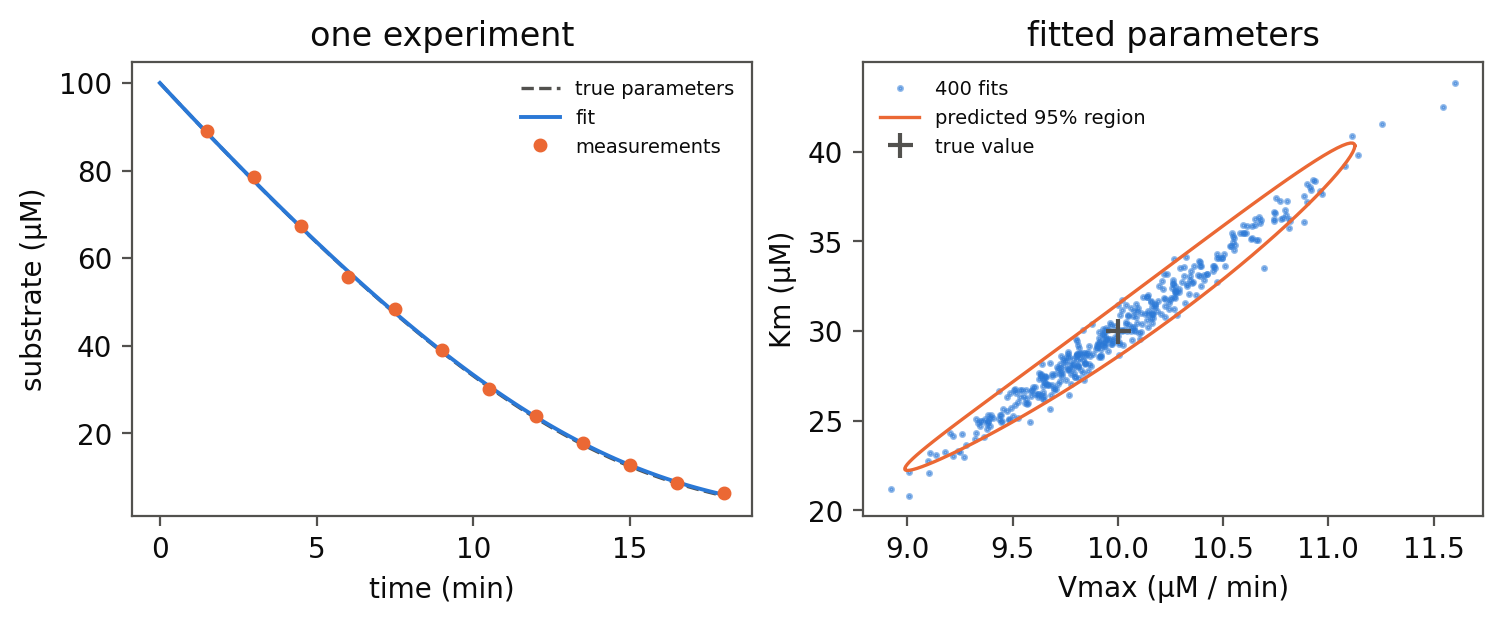
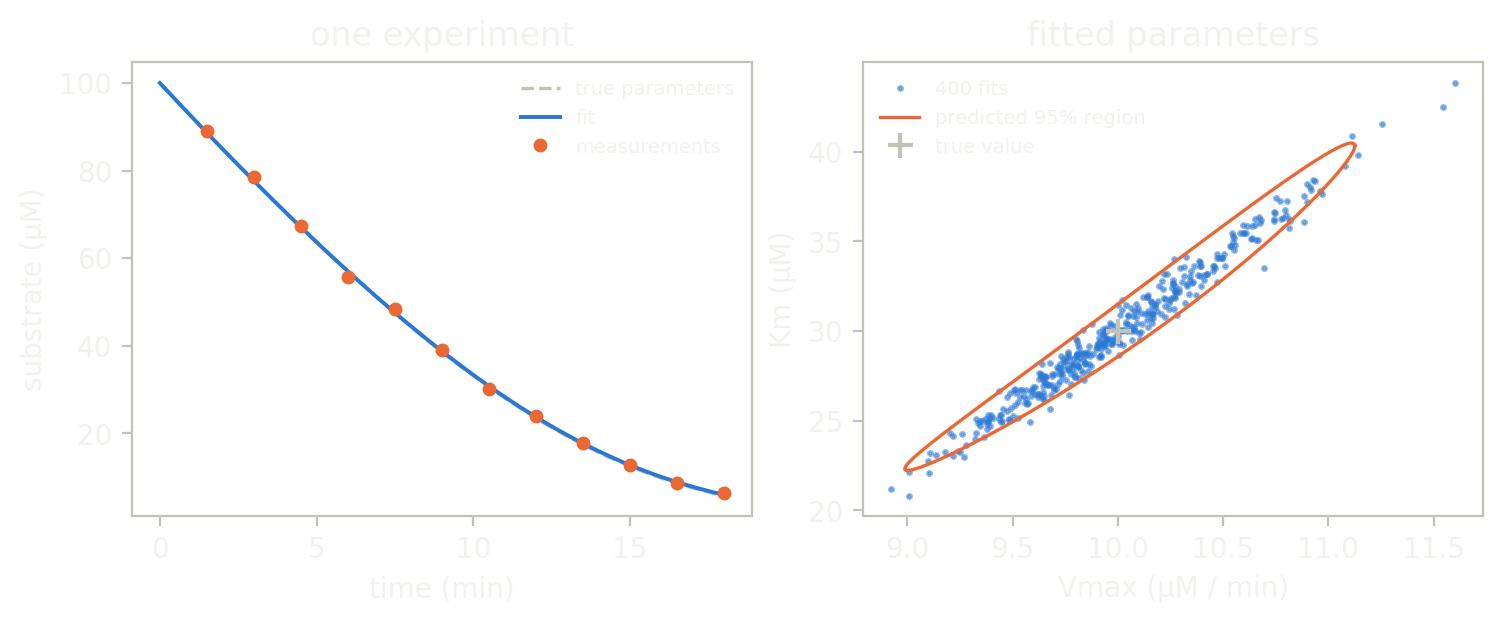

In [10]:
import matplotlib.pyplot as plt

colours = ["#2a78d6", "#eb6834"]
fig, (left, right) = plt.subplots(1, 2, figsize=(7.4, 3.0), constrained_layout=True)
t_fine = np.linspace(0.0, 18, 120)
true_curve = exact_substrate([V_TRUE], [K_TRUE], t_fine)[0][0]
fit_curve = exact_substrate([V_fit[0]], [K_fit[0]], t_fine)[0][0]
left.plot(t_fine, true_curve, "--", lw=1.2, color="#898781", label="true parameters")
left.plot(t_fine, fit_curve, lw=1.4, color=colours[0], label="fit")
left.plot(t_obs, data[0], "o", ms=4, color=colours[1], label="measurements")
left.set_xlabel("time (min)"); left.set_ylabel("substrate (µM)"); left.set_title("one experiment"); left.legend(frameon=False, fontsize=7)

right.plot(V_fit, K_fit, ".", ms=3, alpha=0.5, color=colours[0], label="400 fits")
angle = np.linspace(0, 2 * np.pi, 100)
ring = np.exp(np.log([[V_TRUE], [K_TRUE]]) + np.linalg.cholesky(cov) @ np.stack([np.cos(angle), np.sin(angle)]) * np.sqrt(5.99))
right.plot(*ring, lw=1.2, color=colours[1], label="predicted 95% region")
right.plot([V_TRUE], [K_TRUE], "+", ms=9, mew=1.5, color="#898781", label="true value")
right.set_xlabel("Vmax (µM / min)"); right.set_ylabel("Km (µM)"); right.set_title("fitted parameters"); right.legend(frameon=False, fontsize=7)
show(fig, f"Two panels. Left: substrate in micromolar against time in minutes, falling from {S0:.0f} to about {true_curve[-1]:.0f} over 18 minutes with a gentle flattening; twelve measurements, the fitted curve and the dashed true curve lie on top of each other. Right: fitted Vmax and Km of {N} experiments as a long thin cloud, with the predicted 95 percent ellipse spanning Vmax from {ring[0].min():.1f} to {ring[0].max():.1f} and Km from {ring[1].min():.0f} to {ring[1].max():.0f}, centred on the true value {V_TRUE:g} and {K_TRUE:g}; the cloud lies inside it.")

## The animation

The 400 fits at every Levenberg-Marquardt iteration, as dots in the plane of `Vmax` and `Km`. They all start at the same guess, `Vmax = 6`, `Km = 15`, and the data pull each one along the narrow valley of the misfit to its own maximum-likelihood point, inside the predicted 95% region. The positions come from the same `fit`, which keeps its trail when asked.

In [11]:
from anim import frame_of, write_anim
from themed_figure import DARK, LIGHT

pos = np.exp(np.stack(trail))                                      # (iteration, 2, experiment): Vmax, Km after each iteration
lo, hi = np.percentile(pos[-1], [0.5, 99.5], axis=1)
x_lim = (min(5.0, lo[0] * 0.95), hi[0] * 1.08)
y_lim = (min(13.0, lo[1] * 0.9), hi[1] * 1.08)


def render(theme, k):
    pal = LIGHT if theme == "light" else DARK
    fig = plt.figure(figsize=(5.0, 3.2), facecolor=pal["bg"])
    ax = fig.add_axes([0.13, 0.17, 0.83, 0.76], facecolor=pal["bg"])
    ax.plot(*ring, lw=1.0, color="#eb6834")
    ax.plot([V_TRUE], [K_TRUE], "+", ms=9, mew=1.5, color=pal["sub"])
    if k > 0:
        ax.plot(pos[: k + 1, 0, :60], pos[: k + 1, 1, :60], lw=0.4, color="#2a78d6", alpha=0.35)         # trails of the first 60
    ax.plot(pos[k, 0], pos[k, 1], ".", ms=3.2, color="#2a78d6", alpha=0.7)
    ax.set_xlim(*x_lim); ax.set_ylim(*y_lim)
    ax.set_xlabel("Vmax (µM / min)", color=pal["sub"], fontsize=8); ax.set_ylabel("Km (µM)", color=pal["sub"], fontsize=8)
    ax.tick_params(colors=pal["sub"], labelsize=7)
    for sp in ax.spines.values():
        sp.set_color(pal["rule"])
    ax.text(0.97, 0.06, f"iteration {k} of {len(pos) - 1}", transform=ax.transAxes, ha="right", fontsize=8, color=pal["ink"])
    return frame_of(fig, pal["bg"])


frames_at = list(range(len(pos))) + [len(pos) - 1] * 8
sizes = {}
for theme in ("light", "dark"):
    sizes.update(write_anim([render(theme, k) for k in frames_at], f"enzyme_fits_{theme}", fps=5))
for name, size in sizes.items():
    print(name, f"{size / 1e3:.0f} kB")
assert max(sizes.values()) < 1.5e6

enzyme_fits_light.gif 232 kB
enzyme_fits_dark.gif 207 kB


```{image} ../../_static/anim/enzyme_fits_light.gif
:class: only-light
:alt: Four hundred dots, one per fitted experiment, start together at Vmax 6 and Km 15 and spread out along a narrow diagonal valley to fill the predicted 95 percent ellipse around the true value, in a few iterations
```
```{image} ../../_static/anim/enzyme_fits_dark.gif
:class: only-dark
:alt: Four hundred dots, one per fitted experiment, start together at Vmax 6 and Km 15 and spread out along a narrow diagonal valley to fill the predicted 95 percent ellipse around the true value, in a few iterations
```

## A bigger fit, when a GPU is there

This cell runs only when a GPU is present; on a CPU runtime it prints that and does nothing. The same `fit` runs on device arrays: 20 000 experiments, each the same synthetic design. The spread of the fitted values must again match the Fisher prediction within 10%, now measured much more finely. A maximum-likelihood fit is unbiased only to leading order, and 20 000 fits can resolve the small bias that remains, a few percent of the spread in `ln Vmax`. So the bias is asserted to be under a tenth of the spread, and printed.

In [12]:
if gpu_available():
    big = 20_000
    big_data = xp.asarray(clean + SIGMA * np.random.default_rng(7).normal(size=(big, M)))
    big_theta, _, _, _ = fit(big_data)
    big_err = big_theta - np.log([[V_TRUE], [K_TRUE]])
    bias = big_err.mean(axis=1) / big_err.std(axis=1)
    assert (np.abs(big_err.std(axis=1) / se - 1) < 0.10).all() and (np.abs(bias) < 0.1).all(), (big_err.std(axis=1), bias)
    print(f"{big} experiments fitted on the GPU: spread {big_err.std(axis=1).round(4)} against predicted {se.round(4)}; bias {bias.round(3)} of the spread")
else:
    print("no GPU here; the fit stays at", N, "experiments")

20000 experiments fitted on the GPU: spread [0.0436 0.1224] against predicted [0.0436 0.1225]; bias [0.042 0.006] of the spread


## What just happened

- `Enzyme` named the start substrate, the two rate parameters and the time of a measurement once; `progress` is the integration in those names, one lane per measurement, with RK4 for a rate law whose stiffness the page checks against the stability limit.
- The integrated curves matched the exact Lambert W solution with fourth-order convergence, and the substrate and product summed to `S0` (by construction).
- `vjp` gave the derivatives for fitting, and they matched a finite difference of the same integration to rounding and the closed-form derivative within the scheme's error.
- Levenberg-Marquardt, with `J` from the same `vjp` kernel in one launch, fitted 400 experiments in 30 iterations. The fitted spread matched the Fisher prediction, the chi-squared had the right mean, and the true parameters fell inside each fit's own 95% region for 92.5% of the data sets (95% expected).
- `lm_kernel` took every experiment's damped Gauss-Newton step with `m.lm_step`, so the whole fit runs through hawk kernels. The animation shows the 400 fits leaving the common start and filling the predicted region.

## Try this

Halve the noise (`SIGMA = 0.5`) and the fitted spread should halve too. Or measure only to 6 min, before the substrate has run out: the correlation rises from 0.987 to 0.999 and the uncertainty of `ln Km` grows by a factor of 8, which the identifiability lines report. Both are one-line changes.

## Next

[Combustion](13_combustion) takes a gradient through a stop in a runaway reaction. [Your own derivative](03_your_own_derivative) covers supplying a derivative by hand.